# Import Libraries

In [204]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

# Load Dataset

In [205]:
df = pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


**Pregnancies:** The number of times the patient has been pregnant.

**Glucose:** Plasma glucose concentration (mg/dL) measured two hours into an oral glucose tolerance test.

**BloodPressure:** Diastolic blood pressure (mm Hg).

**SkinThickness:** Triceps skin-fold thickness (mm), used as a rough estimate of body fat.

**Insulin:** Serum insulin level two hours after the glucose test (µU/mL).

**BMI:** Body mass index (weight in kg divided by height in m²), a general measure of body weight relative to height.

**DiabetesPerdigreeFunction:** A score estimating how likely the patient is to have diabetes based on their family history. It’s a weighted ratio of the family members who developed diabetes to those who haven’t.

**Age:** The patient’s age in years.

**Outcome:** The target variable, where 1 means the patient was diagnosed with diabetes and 0 means they were not.

# Plot Variables

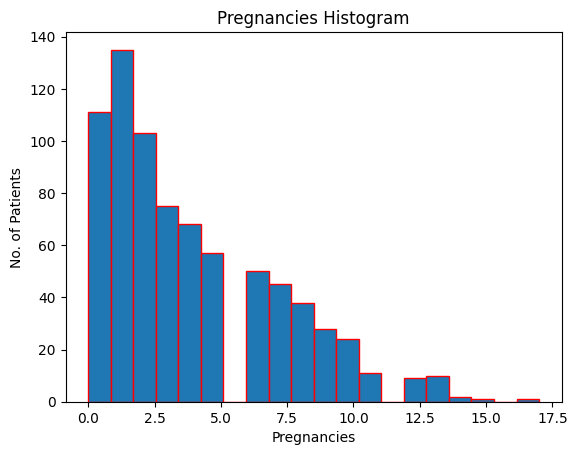

In [206]:
df['Pregnancies'].hist(bins=20,edgecolor='red')
plt.title('Pregnancies Histogram')
plt.xlabel('Pregnancies')
plt.ylabel('No. of Patients')
plt.grid(False)
plt.show()

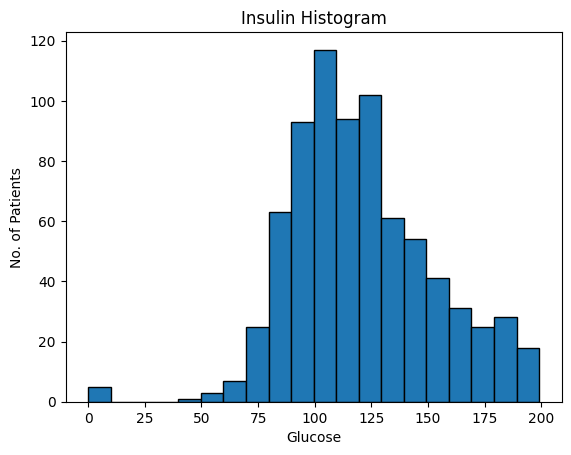

In [207]:
df['Glucose'].hist(bins=20, edgecolor='black')
plt.title('Insulin Histogram')
plt.xlabel('Glucose')
plt.ylabel('No. of Patients')
plt.grid(False)
plt.show()

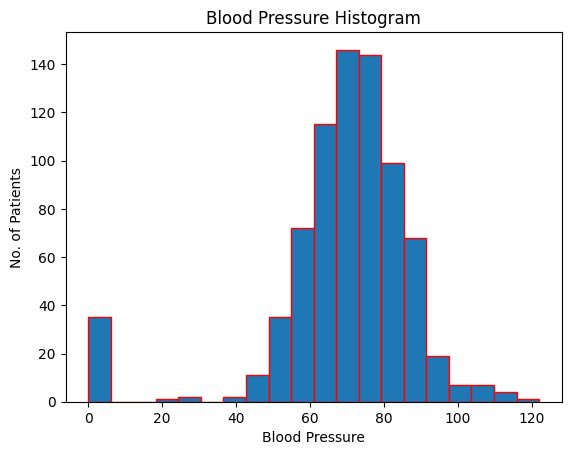

In [208]:
df['BloodPressure'].hist(bins=20,edgecolor='red')
plt.title('Blood Pressure Histogram')
plt.xlabel('Blood Pressure')
plt.ylabel('No. of Patients')
plt.grid(False)
plt.show()

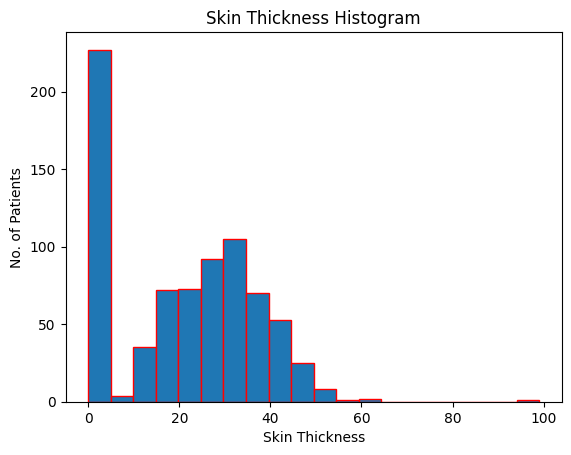

In [209]:
df['SkinThickness'].hist(bins=20,edgecolor='red')
plt.title('Skin Thickness Histogram')
plt.xlabel('Skin Thickness')
plt.ylabel('No. of Patients')
plt.grid(False)
plt.show()

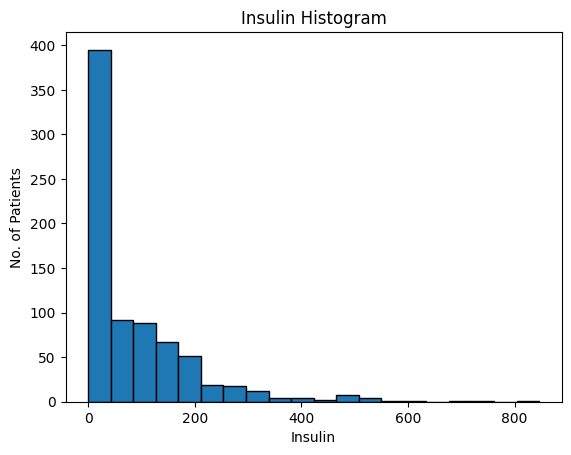

In [210]:
df['Insulin'].hist(bins=20, edgecolor='black')
plt.title('Insulin Histogram')
plt.xlabel('Insulin')
plt.ylabel('No. of Patients')
plt.grid(False)
plt.show()

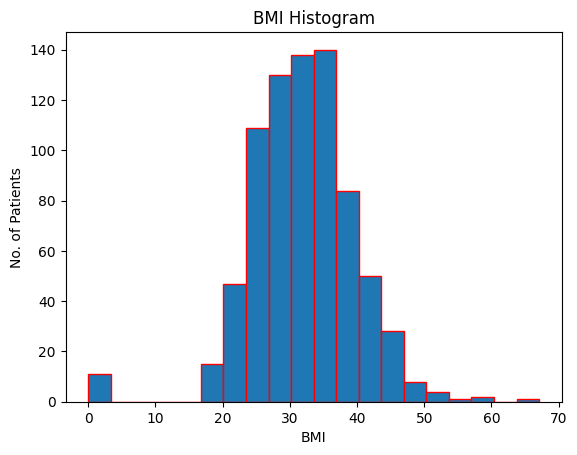

In [211]:
df['BMI'].hist(bins=20,edgecolor='red')
plt.title('BMI Histogram')
plt.xlabel('BMI')
plt.ylabel('No. of Patients')
plt.grid(False)
plt.show()

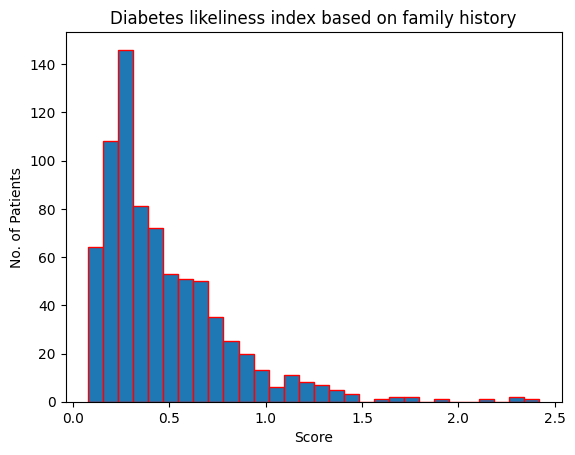

In [212]:
df['DiabetesPedigreeFunction'].hist(bins=30,edgecolor='red')
plt.title('Diabetes likeliness index based on family history')
plt.xlabel('Score')
plt.ylabel('No. of Patients')
plt.grid(False)
plt.show()

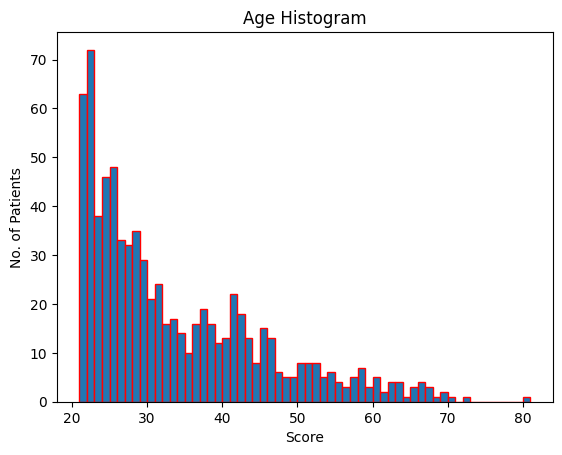

In [213]:
df['Age'].hist(bins=60,edgecolor='red')
plt.title('Age Histogram')
plt.xlabel('Score')
plt.ylabel('No. of Patients')
plt.grid(False)
plt.show()

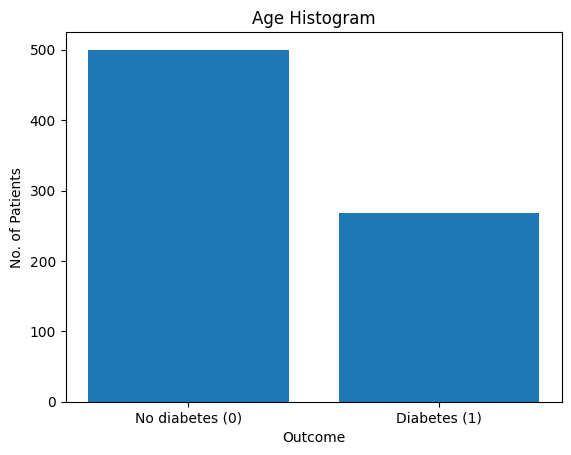

In [214]:
plt.bar(['No diabetes (0)', 'Diabetes (1)'], df['Outcome'].value_counts())
plt.title('Age Histogram')
plt.xlabel('Outcome')
plt.ylabel('No. of Patients')
plt.grid(False)
plt.show()

# Convert DataFrame to Numpy arrays

In [215]:
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((768, 8), (768,))

# Split Dataset to Train-Test

In [216]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape
print("Train Samples: ",len(x_train))
print("Test Samples: ",len(x_test))

Train Samples:  537
Test Samples:  231


# Create a Logistic Regression Model

In [217]:
model = LogisticRegression(max_iter=5000, random_state=seed)

# Train model on training set

In [218]:
model.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=0)

# Evaluate model on training set

In [219]:
y_test_pred= model.predict(x_train)
train_acc= round(accuracy_score(y_train, y_test_pred)*100, 2)
print(f'Accuracy on train set: {train_acc}')

Accuracy on train set: 76.54


# Evaluate Model on test set

In [220]:
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model is: {accuracy_percentage}')

The accuracy of the model is: 77.92


# Feature Importance

Retrain the model using standard scaling. Then, investigate coefficients. Larger coefficient values $\rightarrow$ more important features

## Data Normalization

In [221]:
scaler = StandardScaler()
scaler.fit(x_train)

x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

## Model Training-Evaluation

In [222]:
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model is: {accuracy_percentage}')

The accuracy of the model is: 77.92


# Glucose --> Diabetes relation

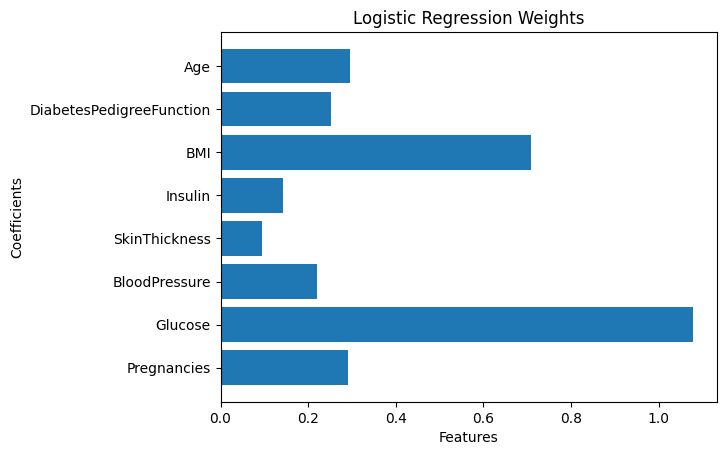

In [223]:
coeffs = model.coef_[0]
importance_weights = np.abs(coeffs)
plt.barh(input_df.columns, importance_weights)
plt.title('Logistic Regression Weights')
plt.xlabel('Features')
plt.ylabel('Coefficients')
plt.show()

Το μοντέλο έκρινε πως η γλυκόζη είναι το σημαντικότερο χαρακτηριστικό και της απέδωσε το υωηλότερο βάρος.

In [224]:
dgluc = df[df['Glucose'] > 0].copy()

print(dgluc.groupby('Outcome')['Glucose'].describe().round(1))

         count   mean   std   min    25%    50%    75%    max
Outcome                                                      
0        497.0  110.6  24.8  44.0   93.0  107.0  125.0  197.0
1        266.0  142.3  29.6  78.0  119.0  140.0  167.0  199.0


Παρατηρείται ότι οι ασθενείς με διαβήτη (Outcome=1) έχουν υψηλότερες τιμές γλυκόζης σε min,max και mean, όπως φαίνεται και στο boxplot παρακάτω.



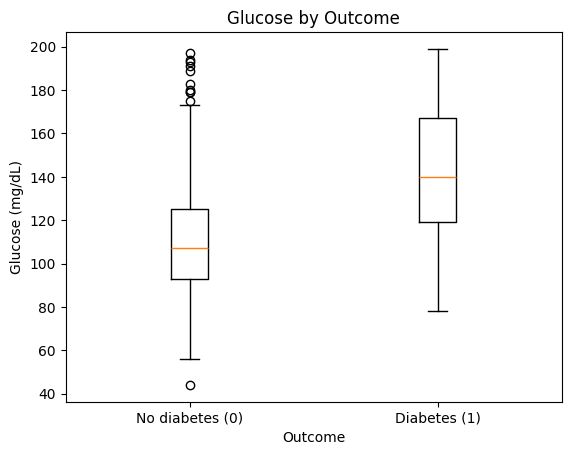

In [225]:
plt.boxplot([dgluc[dgluc['Outcome'] == 0]['Glucose'], dgluc[dgluc['Outcome'] == 1]['Glucose']])
plt.xticks([1, 2], ['No diabetes (0)', 'Diabetes (1)'])
plt.title('Glucose by Outcome')
plt.xlabel('Outcome')
plt.ylabel('Glucose (mg/dL)')
plt.grid(False)
plt.show()

# Classifier Accuracy by Age group

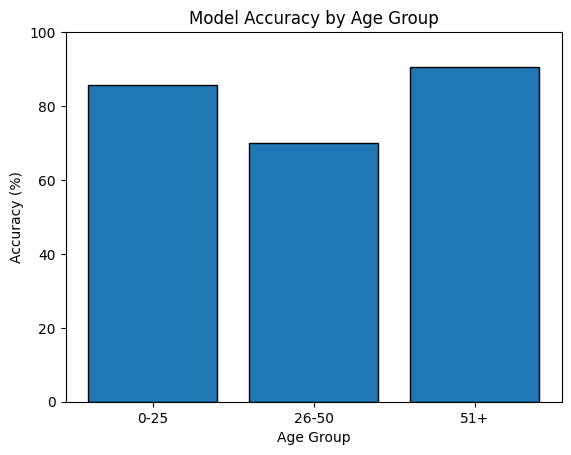

Δείγματα
0-25: 90
26-50: 120
51+: 21


In [226]:
age_test = np.round(scaler.inverse_transform(x_test)[:, 7])
correct = (y_pred == y_test)
groups = {'0-25':  age_test <= 25,
          '26-50': (age_test > 25) & (age_test <= 50),
          '51+':   age_test > 50}

names=[]
accs=[]
for name, mask in groups.items():
    acc = round(correct[mask].mean() * 100, 2)
    names.append(name)
    accs.append(acc)


plt.bar(names, accs, edgecolor='black')
plt.title('Model Accuracy by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.grid(False)
plt.show()

print('Δείγματα')
for name, mask in groups.items():
    print(f'{name}: {mask.sum()}')

Το accuracy του μοντέλου διαφέρει ανά ηλικιακή ομάδα.. Το μοντέλο τα πηγαίνει χειρότερα στη μεσαία ομάδα, όπου η αναλογία διαβητικών και μη διαβητικών είναι πιο ισορροπημένη (50 με διαβήτη έναντι 70 χωρίς). Αντίθετα, στους 0-25 μόνο το 17% έχει διαβήτη, οπότε και μια πρόβλεψη «όχι διαβήτης» για όλους θα έδινε ήδη περίπου 83%. Επιπλέον, η ομάδα 51+ έχει πολύ λίγα δείγματα, οπότε το υψηλό accuracy της δεν είναι αξιόπιστο. Συνολικά, οι διαφορές ανάμεσα στις ομάδες δεν δείχνουν ασφαλώς ότι το μοντέλο λειτουργεί καλύτερα ή χειρότερα σε συγκεκριμένες ηλικίες.





# Τι είναι χειρότερο; False Negatives ή False Positives;

Στη συγκεκριμένη εφαρμογή, επειδή πρόκειται για ιατρική διάγνωση, χειρότερο σενάριο είναι το ψευδώς αρνητικό αποτέλεσμα.

Σε ένα ψευδώς αρνητικό αποτέλεσμα, ο ασθενής με διαβήτη θεωρείται υγιής και δεν ακολουθεί την απαραίτητη θεραπέια, με αποτέλεσμα να υπάρχουν σοβαρές επιπλοκές.